# How-to 1 · RVs of a real star (NRES, TOI-677)

Load 12 NRES echelle spectra, preprocess them with the instrument's recommended settings,
build a matched PHOENIX template and measure one UNICOR RV per epoch.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import CCF1d, Observations, Template, instruments
from sparta.plotting import apply_style, plot_points

apply_style()        # SPARTA figure style: data black, model red, extra blue, maps grey

In [2]:
# Load the 12 NRES spectra
obs = Observations(survey="NRES", target_visits_lib="../data/TOI677/")
# What SPARTA knows about NRES, including its recommended settings
nres = instruments.get("NRES")
rec = nres.recommended                                  # starting-point settings for this product

obs.select_orders(list(rec.drop_orders), remove=True)   # keep the clean orders
obs.preprocess(**rec.preprocess)                        # trim, resample, de-cosmic, band-pass, taper
print(f"{obs.sample_size} epochs, {len(obs.spec_list[0].wv)} orders kept")
print("preprocess:", rec.preprocess)

12 epochs, 40 orders kept
preprocess: {'n_trim': 100, 'clean_margins': True, 'remove_nans': True, 'delta': 0.5, 'cosmic_sigma': 3, 'continuum_scale_kms': 1400.0, 'noise_scale_kms': 9.6, 'alpha': 0.3}


The template: a bundled PHOENIX model (no download), broadened to the star's rotation and to
NRES's resolving power, cut to the observed orders and preprocessed exactly like the data.

In [3]:
# Wavelength span (Å) of the observed orders
spec0 = obs.spec_list[0]
lo, hi = min(w[0] for w in spec0.wv), max(w[-1] for w in spec0.wv)        # Angstrom

# A bundled PHOENIX model, a little wider than the data
template = Template.from_phoenix(5800, 3.5, 0.5, wave_range=(lo - 10, hi + 10),
                                 allow_download=False)
# Broaden to the star's rotation and the instrument's resolution
template.broaden_rotational(vsini=6.0, epsilon=0.5)                       # km/s
template.broaden_instrumental(resolution=nres.instrument.resolving_power)
# Cut into the observed orders and preprocess like the data
template.cut_multiorder_like(spec0, margins=150)
template.model.preprocess(**rec.preprocess)
print(f"template: {len(template.model.wv)} orders, {lo - 10:.0f}-{hi + 10:.0f} Å")

template: 40 orders, 4566-7601 Å


In [4]:
# Cross-correlate every epoch with the template (UNICOR), one RV each
obs.calc_rv_against_template(template, dv=rec.dv_kms, vel_bound=100)     # km/s

# Sort the epochs by time
order = np.argsort(obs.time_list)                       # files are not in time order
t, rv, erv = np.asarray(obs.time_list)[order], obs.vels[order], obs.evels[order]
# RV ± error per epoch, and the scatter of the series
for ti, r, e in zip(t, rv, erv):
    print(f"t = {ti:7.3f} d   RV = {r:8.3f} ± {e:.3f} km/s")
print(f"mean RV {rv.mean():.3f} km/s, rms {rv.std() * 1e3:.0f} m/s, "
      f"median eRV {np.median(erv) * 1e3:.0f} m/s")

t =   0.565 d   RV =   38.313 ± 0.025 km/s
t =   1.534 d   RV =   38.229 ± 0.026 km/s
t =   2.537 d   RV =   38.146 ± 0.020 km/s
t =   3.520 d   RV =   38.177 ± 0.021 km/s
t =  18.524 d   RV =   38.084 ± 0.020 km/s
t =  19.524 d   RV =   38.173 ± 0.022 km/s
t =  20.513 d   RV =   38.200 ± 0.021 km/s
t =  21.504 d   RV =   38.236 ± 0.025 km/s
t =  27.494 d   RV =   38.008 ± 0.025 km/s
t =  29.456 d   RV =   38.194 ± 0.024 km/s
t =  30.495 d   RV =   38.242 ± 0.025 km/s
t =  31.476 d   RV =   38.187 ± 0.029 km/s
mean RV 38.182 km/s, rms 75 m/s, median eRV 24 m/s


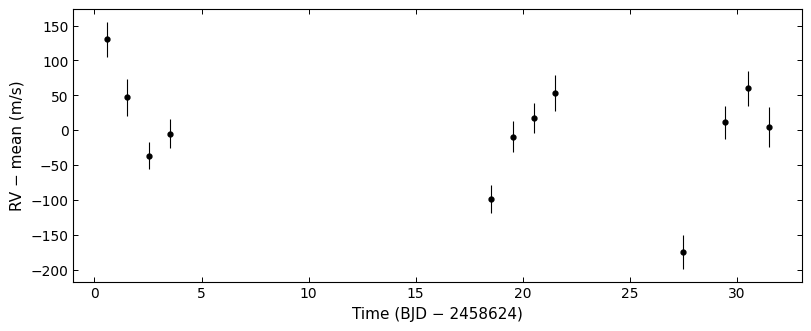

In [5]:
# The RV series with the mean removed (m/s)
fig, ax = plt.subplots()
plot_points(ax, t, (rv - rv.mean()) * 1e3, erv * 1e3)
ax.set_xlabel(f"Time (BJD − {obs.first_time})")
ax.set_ylabel("RV − mean (m/s)")
plt.show()

The CCFs of the first epoch: each order (faint) and their maximum-likelihood combination
(bold), with the RV ± eRV in red.

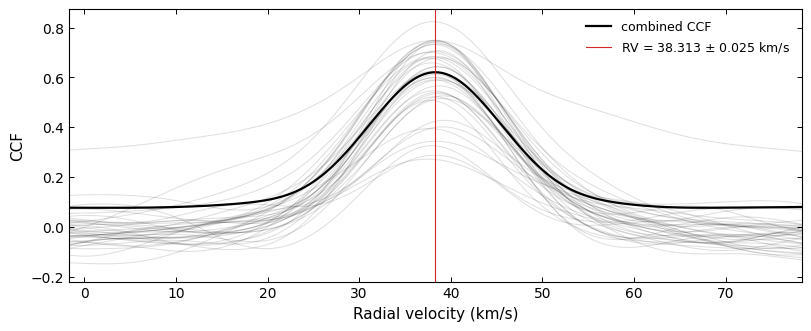

In [6]:
# The CCFs of the earliest epoch, zoomed around its RV
first = obs.ccf_list[order[0]]
fig = first.plot()
fig.axes[0].set_xlim(rv[0] - 40, rv[0] + 40)
plt.show()

`output='loglike'` stores the Zucker (2003) log-likelihood as the primary curve instead of the
CCF; the RV and its error are the same:

In [7]:
# The same epoch with the log-likelihood output; the RV must not change
lnl = CCF1d().cross_correlate(spec0, template, dv=rec.dv_kms, vel_bound=100, output="loglike").combine()
print(f"loglike: RV = {lnl.CorrCombined['RV']:.4f} km/s; "
      f"same as the CCF run: {lnl.CorrCombined['RV'] == obs.vels[0]}")

loglike: RV = 38.3128 km/s; same as the CCF run: True


## Go deeper

- How UNICOR measures an RV and its error, built step by step: tutorial [`03_unicor`](../tutorials/03_unicor.ipynb); why it needs a log-λ grid: [`02_log_lambda`](../tutorials/02_log_lambda.ipynb).
- The CCF, the order combination and the two output modes: [correlation engines § UNICOR](../../docs/correlation_engines.md#unicor-ccf1d).
- Why the error bars are not calibrated after `preprocess`: [conventions](../../docs/conventions.md#when-are-the-error-bars-calibrated).
- NRES frames, sampling and the recommended settings: [instruments § NRES](../../docs/instruments.md#nres).
- The checklist for an RV run: [good practices](../../docs/good_practices.md#radial-velocities).